In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 05d — Compare all models (rounds 1–5): 3-channel, year-context and window-context models

Evaluates **every finished run** on the validation and test patches of `data_r5/` (the same val/test regions as
`data_r3`). Each model is evaluated with **the normalisation statistics and input features of the data it was
trained on** (`data`, `data_r3` or `data_r5`), so old and new models are compared fairly.

Per-region tables show mIoU over the classes present in each region's labels **and** per-region OA.
Outputs go to **`runs/comparison_r5/`** (earlier comparison folders are kept). Model weights are only read.

**Rules for reading it**
* Choose by **validation mIoU**; test numbers are for the report.
* Gaps under ~0.02–0.03 mIoU are likely noise.
* Look at the per-month table too: models with whole-year context are flat across months (stable, but may hide real change).

In [1]:
import sys, json
sys.path.append(".")
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import train_lib_r5 as tl
from train_lib_r5 import NC, DEV
from preprocess import CLASSES, IGNORE, COLORS, load_stats

DATA = Path("data_r5")
OUT = Path("runs") / "comparison_r5"; OUT.mkdir(parents=True, exist_ok=True)
stats = load_stats(DATA / "norm_stats.json")
index = pd.read_csv(DATA / "patch_index.csv")
index["file"] = index["file"].str.replace("\\", "/", regex=False)

runs = {}
for d in sorted(Path("runs").iterdir()):
    if not (d / "best.pth").exists() or not (d / "config.json").exists():
        continue
    cfg = json.load(open(d / "config.json"))
    if "RUN_NAME" not in cfg or tl.arch_of(cfg) is None:      # skips the old 03_training runs
        continue
    if not d.name.startswith(("A_", "B_", "C_")):
        continue
    runs[cfg["RUN_NAME"]] = cfg
print(f"{len(runs)} runs found:", list(runs))
print("val regions:", sorted(index[index.split == 'val'].region.unique()))
print("test regions:", sorted(index[index.split == 'test'].region.unique()))

13 runs found: ['A_unet_resnet34', 'A_unet_v2', 'A_unet_v4', 'A_unet_v4b', 'B_deeplab_v2', 'B_deeplabv3plus_resnet50', 'C_segformer_mitb2', 'C_segformer_v2', 'C_segformer_v3', 'C_segformer_v4', 'C_segformer_v4b', 'C_segformer_v5', 'C_segformer_v5b']
val regions: ['bangkok', 'danube_delta', 'iowa', 'las_vegas', 'madrid', 'saskatchewan', 'serengeti', 'sudd_wetland']
test regions: ['black_forest', 'cairo', 'hungary_plain', 'mekong_delta', 'namib_desert', 'okavango']


## 1. Evaluate every run on validation and test

In [2]:
_cache = {}
def norm_for(cfg):
    """Normalisation stats + context-channel stats of the data folder this run was trained on."""
    d = Path(cfg.get("DATA", "data")); kind = tl.feature_kind(cfg)
    if not ((d / "norm_stats.json").exists() and (d / "patch_index.csv").exists()):
        print(f"  note: {d}/ not found for {cfg['RUN_NAME']} -> using {DATA}/ statistics instead")
        d = DATA
    key = (str(d), kind)
    if key not in _cache:
        idx = pd.read_csv(d / "patch_index.csv"); idx["file"] = idx["file"].str.replace("\\", "/", regex=False)
        _cache[key] = (load_stats(d / "norm_stats.json"), kind, tl.feature_stats(idx, d, kind))
    return _cache[key]

def load_split(split):
    files = index[index.split == split].reset_index(drop=True)
    ds = tl.EvalPatches(files.file, DATA, desc=f"loading {split}")
    return ds, np.repeat(files.region.values, 12), np.array(ds.month)

val_ds, val_region, val_month = load_split("val")
test_ds, test_region, test_month = load_split("test")

@torch.no_grad()
def run_eval(model, ds, region_of, month_of):
    dl = torch.utils.data.DataLoader(ds, 32, shuffle=False)
    cm_all = torch.zeros(NC, NC, dtype=torch.long, device=DEV)
    cm_reg = {r: torch.zeros_like(cm_all) for r in np.unique(region_of)}
    cm_mon = {m: torch.zeros_like(cm_all) for m in range(12)}
    k = 0
    for x, y in dl:
        x, y = x.to(DEV), y.to(DEV)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
            p = model(x).argmax(1)
        for b in range(len(x)):
            c = tl.confusion(p[b], y[b])
            cm_all += c; cm_reg[region_of[k]] += c; cm_mon[month_of[k]] += c; k += 1
    oa, iou, f1 = tl.scores(cm_all)
    return dict(cm=cm_all, oa=oa, miou=float(iou.mean()), iou=iou, f1=f1,
                region={r: tl.miou_label(c) for r, c in cm_reg.items()},
                region_oa={r: tl.oa_of(c) for r, c in cm_reg.items()},
                month={m + 1: tl.miou_label(c) for m, c in cm_mon.items()})

R = {}
for name, cfg in runs.items():
    in_ch = tl.in_channels_of(cfg)
    s, kind, fs = norm_for(cfg)
    val_ds.configure(s, kind, fs); test_ds.configure(s, kind, fs)
    model = tl.build_model(tl.arch_of(cfg), None, in_ch).to(DEV)
    model.load_state_dict(torch.load(Path("runs") / name / "best.pth", map_location=DEV)); model.eval()
    R[name] = dict(cfg=cfg, val=run_eval(model, val_ds, val_region, val_month),
                   test=run_eval(model, test_ds, test_region, test_month),
                   params=tl.count_params(model))
    h = pd.read_csv(Path("runs") / name / "history.csv")
    R[name]["epochs"], R[name]["minutes"] = len(h), h.seconds.sum() / 60
    print(f"{name:26s} val mIoU {R[name]['val']['miou']:.3f} | test mIoU {R[name]['test']['miou']:.3f}")
    del model
    if DEV == "cuda": torch.cuda.empty_cache()

loading val:   0%|          | 0/128 [00:00<?, ?it/s]

loading test:   0%|          | 0/96 [00:00<?, ?it/s]

A_unet_resnet34            val mIoU 0.430 | test mIoU 0.577
A_unet_v2                  val mIoU 0.488 | test mIoU 0.625
A_unet_v4                  val mIoU 0.568 | test mIoU 0.637
A_unet_v4b                 val mIoU 0.517 | test mIoU 0.639
B_deeplab_v2               val mIoU 0.500 | test mIoU 0.610
B_deeplabv3plus_resnet50   val mIoU 0.497 | test mIoU 0.605
C_segformer_mitb2          val mIoU 0.502 | test mIoU 0.534
C_segformer_v2             val mIoU 0.536 | test mIoU 0.616
C_segformer_v3             val mIoU 0.543 | test mIoU 0.618
C_segformer_v4             val mIoU 0.613 | test mIoU 0.690
C_segformer_v4b            val mIoU 0.570 | test mIoU 0.636
C_segformer_v5             val mIoU 0.626 | test mIoU 0.722
C_segformer_v5b            val mIoU 0.580 | test mIoU 0.598


## 2. Summary tables

In [3]:
summary = pd.DataFrame({n: {"model": r["cfg"].get("MODEL_NAME", n), "group": r["cfg"].get("GROUP", n),
                            "val OA": r["val"]["oa"], "val mIoU": r["val"]["miou"],
                            "test OA": r["test"]["oa"], "test mIoU": r["test"]["miou"],
                            "params (M)": r["params"], "epochs": r["epochs"], "train min": r["minutes"],
                            "loss": r["cfg"].get("LOSS", "dice" if r["cfg"].get("USE_DICE", True) else "none"),
                            "LR": r["cfg"].get("LR"), "inputs": r["cfg"].get("FEATURES", "monthly"),
                            "trained on": r["cfg"].get("DATA", "data")}
                        for n, r in R.items()}).T
for c in ["val OA", "val mIoU", "test OA", "test mIoU", "params (M)", "train min"]:
    summary[c] = summary[c].astype(float).round(3)
summary = summary.sort_values("val mIoU", ascending=False)
summary.to_csv(OUT / "comparison_summary.csv")
display(summary)
print("Best by validation mIoU:", summary.index[0])

groups = summary.groupby("group")[["val mIoU", "test mIoU"]].agg(["mean", "std", "count"]).round(3)
if (groups[("val mIoU", "count")] > 1).any():
    print("\nGroups with repeated seeds (mean ± std):"); display(groups)

,model,group,val OA,val mIoU,test OA,test mIoU,params (M),epochs,train min,loss,LR,inputs,trained on
C_segformer_v5,"SegFormer / MiT-B2 v5 (+year, more regions)",C_segformer_v5,0.822,0.626,0.837,0.722,24.736,29,39.816,lovasz,0.00006,monthly+year,data_r5
C_segformer_v4,SegFormer / MiT-B2 v4 (+year),C_segformer_v4,0.804,0.613,0.811,0.690,24.736,32,28.460,lovasz,0.00006,monthly+year,data_r3
C_segformer_v5b,"SegFormer / MiT-B2 v5b (+3-month window, more ...",C_segformer_v5b,0.786,0.580,0.742,0.598,24.736,31,36.744,lovasz,0.00006,monthly+window3,data_r5
C_segformer_v4b,SegFormer / MiT-B2 v4b (+3-month window),C_segformer_v4b,0.782,0.570,0.764,0.636,24.736,32,28.458,lovasz,0.00006,monthly+window3,data_r3
A_unet_v4,U-Net / ResNet-34 v4 (+year),A_unet_v4,0.780,0.568,0.784,0.637,24.450,30,23.761,lovasz,0.0003,monthly+year,data_r3
C_segformer_v3,SegFormer / MiT-B2 v3,C_segformer_v3,0.764,0.543,0.756,0.618,24.724,48,12.311,lovasz,0.00006,monthly,data_r3
C_segformer_v2,SegFormer / MiT-B2 v2,C_segformer_v2,0.761,0.536,0.754,0.616,24.724,42,8.826,lovasz,0.0001,monthly,data_r3
A_unet_v4b,U-Net / ResNet-34 v4b (+3-month window),A_unet_v4b,0.732,0.517,0.769,0.639,24.450,44,34.643,lovasz,0.0003,monthly+window3,data_r3
C_segformer_mitb2,SegFormer / MiT-B2,C_segformer_mitb2,0.723,0.502,0.666,0.534,24.724,15,2.987,dice,0.0001,monthly,data
B_deeplab_v2,DeepLabV3+ / ResNet-50 v2,B_deeplab_v2,0.730,0.500,0.748,0.610,26.679,60,12.424,lovasz,0.0003,monthly,data_r3


Best by validation mIoU: C_segformer_v5


In [4]:
val_iou  = pd.DataFrame({n: r["val"]["iou"]  for n, r in R.items()}, index=CLASSES).T.round(3).loc[summary.index]
test_iou = pd.DataFrame({n: r["test"]["iou"] for n, r in R.items()}, index=CLASSES).T.round(3).loc[summary.index]
test_f1  = pd.DataFrame({n: r["test"]["f1"]  for n, r in R.items()}, index=CLASSES).T.round(3).loc[summary.index]
val_iou.to_csv(OUT / "comparison_val_iou.csv"); test_iou.to_csv(OUT / "comparison_test_iou.csv"); test_f1.to_csv(OUT / "comparison_test_f1.csv")
print("Validation IoU per class"); display(val_iou.style.highlight_max(axis=0, color="#cde8cd"))
print("Test IoU per class");       display(test_iou.style.highlight_max(axis=0, color="#cde8cd"))
print("Test F1 per class");        display(test_f1.style.highlight_max(axis=0, color="#cde8cd"))

Validation IoU per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
C_segformer_v5,0.413000,0.676000,0.661000,0.780000,0.266000,0.737000,0.851000
C_segformer_v4,0.409000,0.616000,0.622000,0.779000,0.310000,0.746000,0.807000
C_segformer_v5b,0.410000,0.616000,0.574000,0.783000,0.256000,0.707000,0.715000
C_segformer_v4b,0.378000,0.604000,0.517000,0.772000,0.268000,0.708000,0.744000
A_unet_v4,0.373000,0.572000,0.537000,0.771000,0.252000,0.730000,0.741000
C_segformer_v3,0.337000,0.593000,0.419000,0.775000,0.255000,0.694000,0.727000
C_segformer_v2,0.351000,0.589000,0.377000,0.776000,0.247000,0.697000,0.718000
A_unet_v4b,0.343000,0.495000,0.380000,0.767000,0.245000,0.702000,0.684000
C_segformer_mitb2,0.396000,0.454000,0.381000,0.757000,0.202000,0.684000,0.639000
B_deeplab_v2,0.344000,0.527000,0.300000,0.767000,0.230000,0.689000,0.642000


Test IoU per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
C_segformer_v5,0.686000,0.487000,0.716000,0.828000,0.970000,0.819000,0.547000
C_segformer_v4,0.681000,0.359000,0.747000,0.810000,0.967000,0.806000,0.458000
C_segformer_v5b,0.639000,0.293000,0.652000,0.807000,0.749000,0.811000,0.236000
C_segformer_v4b,0.643000,0.300000,0.692000,0.816000,0.933000,0.805000,0.260000
A_unet_v4,0.651000,0.363000,0.767000,0.792000,0.831000,0.696000,0.361000
C_segformer_v3,0.614000,0.252000,0.650000,0.821000,0.882000,0.810000,0.300000
C_segformer_v2,0.637000,0.297000,0.656000,0.824000,0.853000,0.811000,0.234000
A_unet_v4b,0.587000,0.298000,0.659000,0.808000,0.961000,0.836000,0.326000
C_segformer_mitb2,0.554000,0.211000,0.591000,0.694000,0.650000,0.762000,0.275000
B_deeplab_v2,0.610000,0.271000,0.610000,0.815000,0.844000,0.811000,0.308000


Test F1 per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
C_segformer_v5,0.814000,0.655000,0.834000,0.906000,0.985000,0.900000,0.707000
C_segformer_v4,0.810000,0.528000,0.855000,0.895000,0.983000,0.892000,0.628000
C_segformer_v5b,0.780000,0.453000,0.789000,0.893000,0.856000,0.896000,0.382000
C_segformer_v4b,0.783000,0.461000,0.818000,0.899000,0.965000,0.892000,0.413000
A_unet_v4,0.788000,0.533000,0.868000,0.884000,0.908000,0.821000,0.530000
C_segformer_v3,0.761000,0.403000,0.788000,0.902000,0.937000,0.895000,0.462000
C_segformer_v2,0.779000,0.458000,0.793000,0.903000,0.921000,0.895000,0.380000
A_unet_v4b,0.740000,0.459000,0.795000,0.894000,0.980000,0.911000,0.492000
C_segformer_mitb2,0.713000,0.348000,0.743000,0.819000,0.788000,0.865000,0.431000
B_deeplab_v2,0.758000,0.427000,0.758000,0.898000,0.915000,0.896000,0.471000


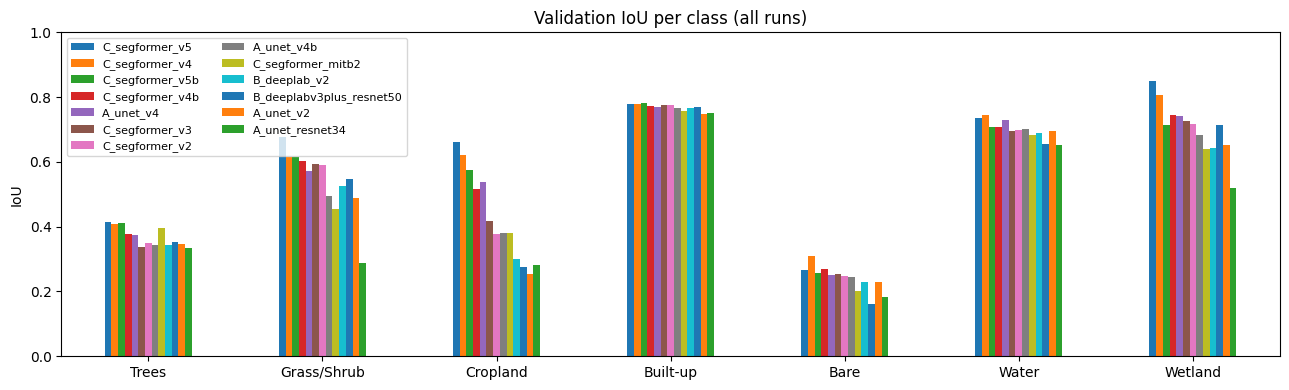

In [5]:
ax = val_iou.T.plot.bar(figsize=(13, 4), rot=0, title="Validation IoU per class (all runs)")
ax.set_ylabel("IoU"); ax.set_ylim(0, 1); ax.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig(OUT / "comparison_val_iou.png", dpi=150); plt.show()

## 3. Training curves

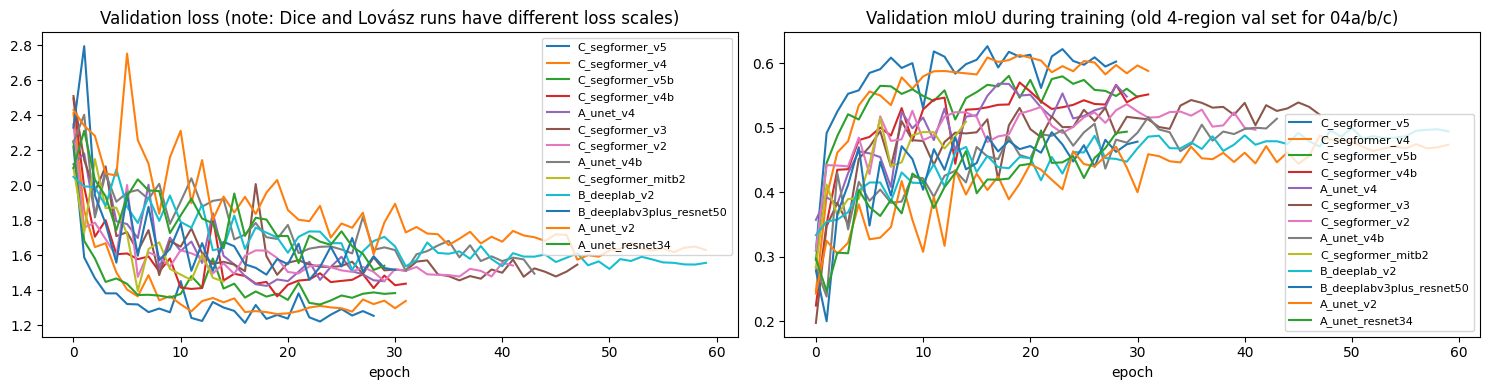

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for name in summary.index:
    h = pd.read_csv(Path("runs") / name / "history.csv")
    ax[0].plot(h.epoch, h.val_loss, label=name); ax[1].plot(h.epoch, h.val_miou, label=name)
ax[0].set_title("Validation loss (note: Dice and Lovász runs have different loss scales)")
ax[1].set_title("Validation mIoU during training (old 4-region val set for 04a/b/c)")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "comparison_curves.png", dpi=150); plt.show()

## 4. Per region and per month (test)
* **Per region:** low values = poor generalisation to that kind of landscape.
* **Per month:** dips (often December–February) = **seasonal confusion**, which the prototype would report as fake land-cover change.

Test mIoU per region (classes present in the region's labels)


,C_segformer_v5,C_segformer_v4,C_segformer_v5b,C_segformer_v4b,A_unet_v4,C_segformer_v3,C_segformer_v2,A_unet_v4b,C_segformer_mitb2,B_deeplab_v2,B_deeplabv3plus_resnet50,A_unet_v2,A_unet_resnet34
black_forest,0.264,0.287,0.254,0.253,0.277,0.268,0.269,0.237,0.222,0.245,0.240,0.258,0.222
cairo,0.420,0.395,0.367,0.348,0.270,0.348,0.346,0.370,0.262,0.345,0.319,0.311,0.274
hungary_plain,0.433,0.425,0.384,0.383,0.446,0.370,0.396,0.414,0.301,0.389,0.347,0.391,0.345
mekong_delta,0.364,0.352,0.338,0.333,0.329,0.349,0.336,0.330,0.299,0.335,0.325,0.334,0.328
namib_desert,0.333,0.333,0.259,0.322,0.335,0.310,0.301,0.332,0.226,0.293,0.320,0.325,0.304
okavango,0.266,0.251,0.238,0.175,0.217,0.210,0.185,0.187,0.161,0.195,0.226,0.183,0.112


Test OA per region


,C_segformer_v5,C_segformer_v4,C_segformer_v5b,C_segformer_v4b,A_unet_v4,C_segformer_v3,C_segformer_v2,A_unet_v4b,C_segformer_mitb2,B_deeplab_v2,B_deeplabv3plus_resnet50,A_unet_v2,A_unet_resnet34
black_forest,0.840,0.888,0.821,0.852,0.864,0.841,0.843,0.815,0.824,0.820,0.828,0.850,0.782
cairo,0.925,0.908,0.907,0.914,0.874,0.913,0.913,0.909,0.766,0.918,0.840,0.854,0.751
hungary_plain,0.823,0.839,0.781,0.776,0.846,0.748,0.777,0.781,0.636,0.747,0.693,0.739,0.686
mekong_delta,0.770,0.748,0.746,0.739,0.735,0.747,0.747,0.713,0.693,0.723,0.709,0.714,0.728
namib_desert,0.998,0.998,0.772,0.967,0.997,0.926,0.901,0.994,0.676,0.876,0.960,0.971,0.907
okavango,0.664,0.485,0.426,0.337,0.389,0.363,0.344,0.401,0.400,0.401,0.413,0.407,0.445


Validation mIoU per region


,C_segformer_v5,C_segformer_v4,C_segformer_v5b,C_segformer_v4b,A_unet_v4,C_segformer_v3,C_segformer_v2,A_unet_v4b,C_segformer_mitb2,B_deeplab_v2,B_deeplabv3plus_resnet50,A_unet_v2,A_unet_resnet34
bangkok,0.269,0.278,0.264,0.259,0.227,0.242,0.247,0.259,0.256,0.241,0.255,0.264,0.247
danube_delta,0.369,0.368,0.280,0.304,0.341,0.294,0.304,0.277,0.287,0.296,0.282,0.279,0.284
iowa,0.404,0.440,0.376,0.390,0.414,0.357,0.363,0.375,0.334,0.335,0.328,0.358,0.345
las_vegas,0.265,0.252,0.250,0.225,0.238,0.210,0.239,0.228,0.207,0.237,0.212,0.222,0.224
madrid,0.345,0.342,0.317,0.325,0.317,0.303,0.302,0.293,0.312,0.317,0.308,0.308,0.303
saskatchewan,0.277,0.284,0.265,0.214,0.250,0.186,0.169,0.178,0.150,0.136,0.113,0.121,0.113
serengeti,0.169,0.137,0.161,0.151,0.135,0.159,0.163,0.126,0.117,0.145,0.155,0.132,0.047
sudd_wetland,0.244,0.256,0.284,0.278,0.266,0.283,0.287,0.265,0.293,0.307,0.281,0.283,0.281


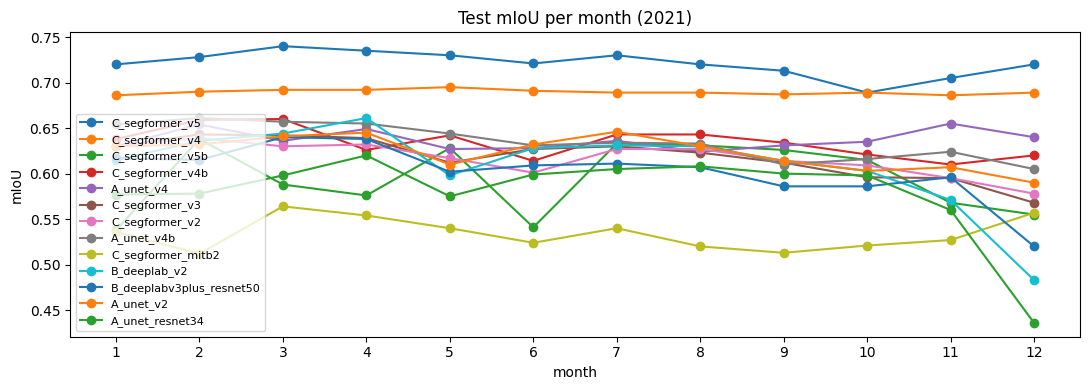

Spread over the year (max - min mIoU), smaller = more seasonally stable:


,spread
C_segformer_v4,0.009
A_unet_v4,0.031
C_segformer_v4b,0.050
C_segformer_v5,0.051
C_segformer_mitb2,0.052
A_unet_v4b,0.056
A_unet_v2,0.056
C_segformer_v2,0.061
C_segformer_v3,0.075
C_segformer_v5b,0.100


In [7]:
by_region = pd.DataFrame({n: r["test"]["region"] for n, r in R.items()}).round(3)[summary.index]
by_month  = pd.DataFrame({n: r["test"]["month"]  for n, r in R.items()}).round(3)[summary.index]
val_region_tab = pd.DataFrame({n: r["val"]["region"] for n, r in R.items()}).round(3)[summary.index]
region_oa = pd.DataFrame({n: r["test"]["region_oa"] for n, r in R.items()}).round(3)[summary.index]
by_region.to_csv(OUT / "comparison_test_by_region.csv"); by_month.to_csv(OUT / "comparison_test_by_month.csv")
val_region_tab.to_csv(OUT / "comparison_val_by_region.csv"); region_oa.to_csv(OUT / "comparison_test_oa_by_region.csv")
print("Test mIoU per region (classes present in the region's labels)"); display(by_region)
print("Test OA per region");                                              display(region_oa)
print("Validation mIoU per region");                                      display(val_region_tab)

ax = by_month.plot(marker="o", figsize=(11, 4), title="Test mIoU per month (2021)")
ax.set_xlabel("month"); ax.set_ylabel("mIoU"); ax.set_xticks(range(1, 13)); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "comparison_test_by_month.png", dpi=150); plt.show()
print("Spread over the year (max - min mIoU), smaller = more seasonally stable:")
display((by_month.max() - by_month.min()).round(3).sort_values().to_frame("spread"))

## 5. Confusion matrices (test) — top 3 runs by validation mIoU

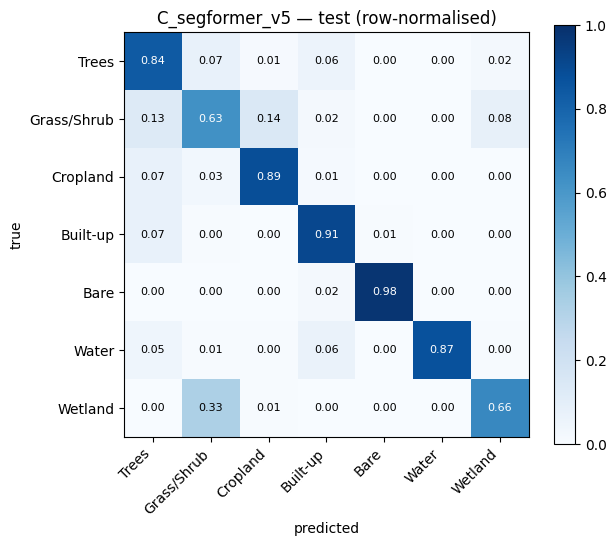

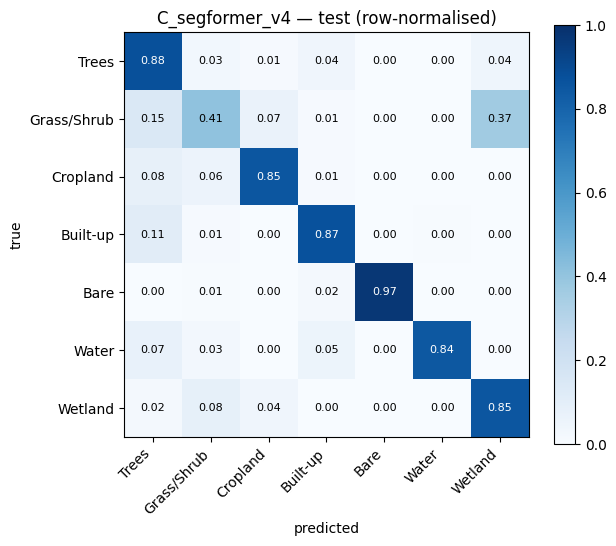

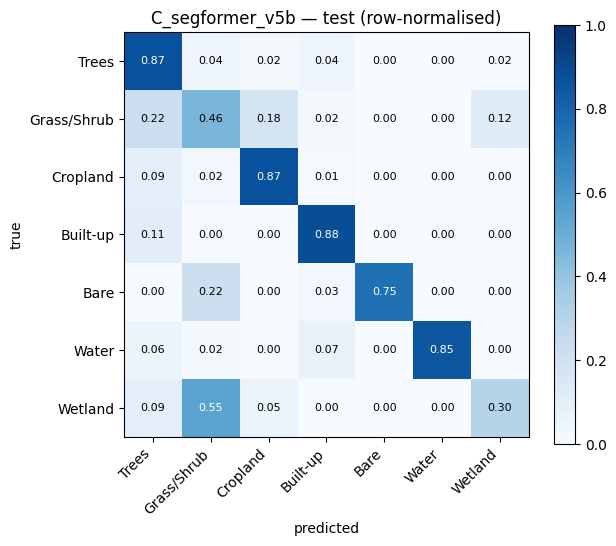

In [8]:
for name in summary.index[:3]:
    tl.plot_confusion(R[name]["test"]["cm"], OUT / f"test_confusion_{name}.png",
                      f"{name} — test (row-normalised)")

## 6. Same test patches, top 4 runs

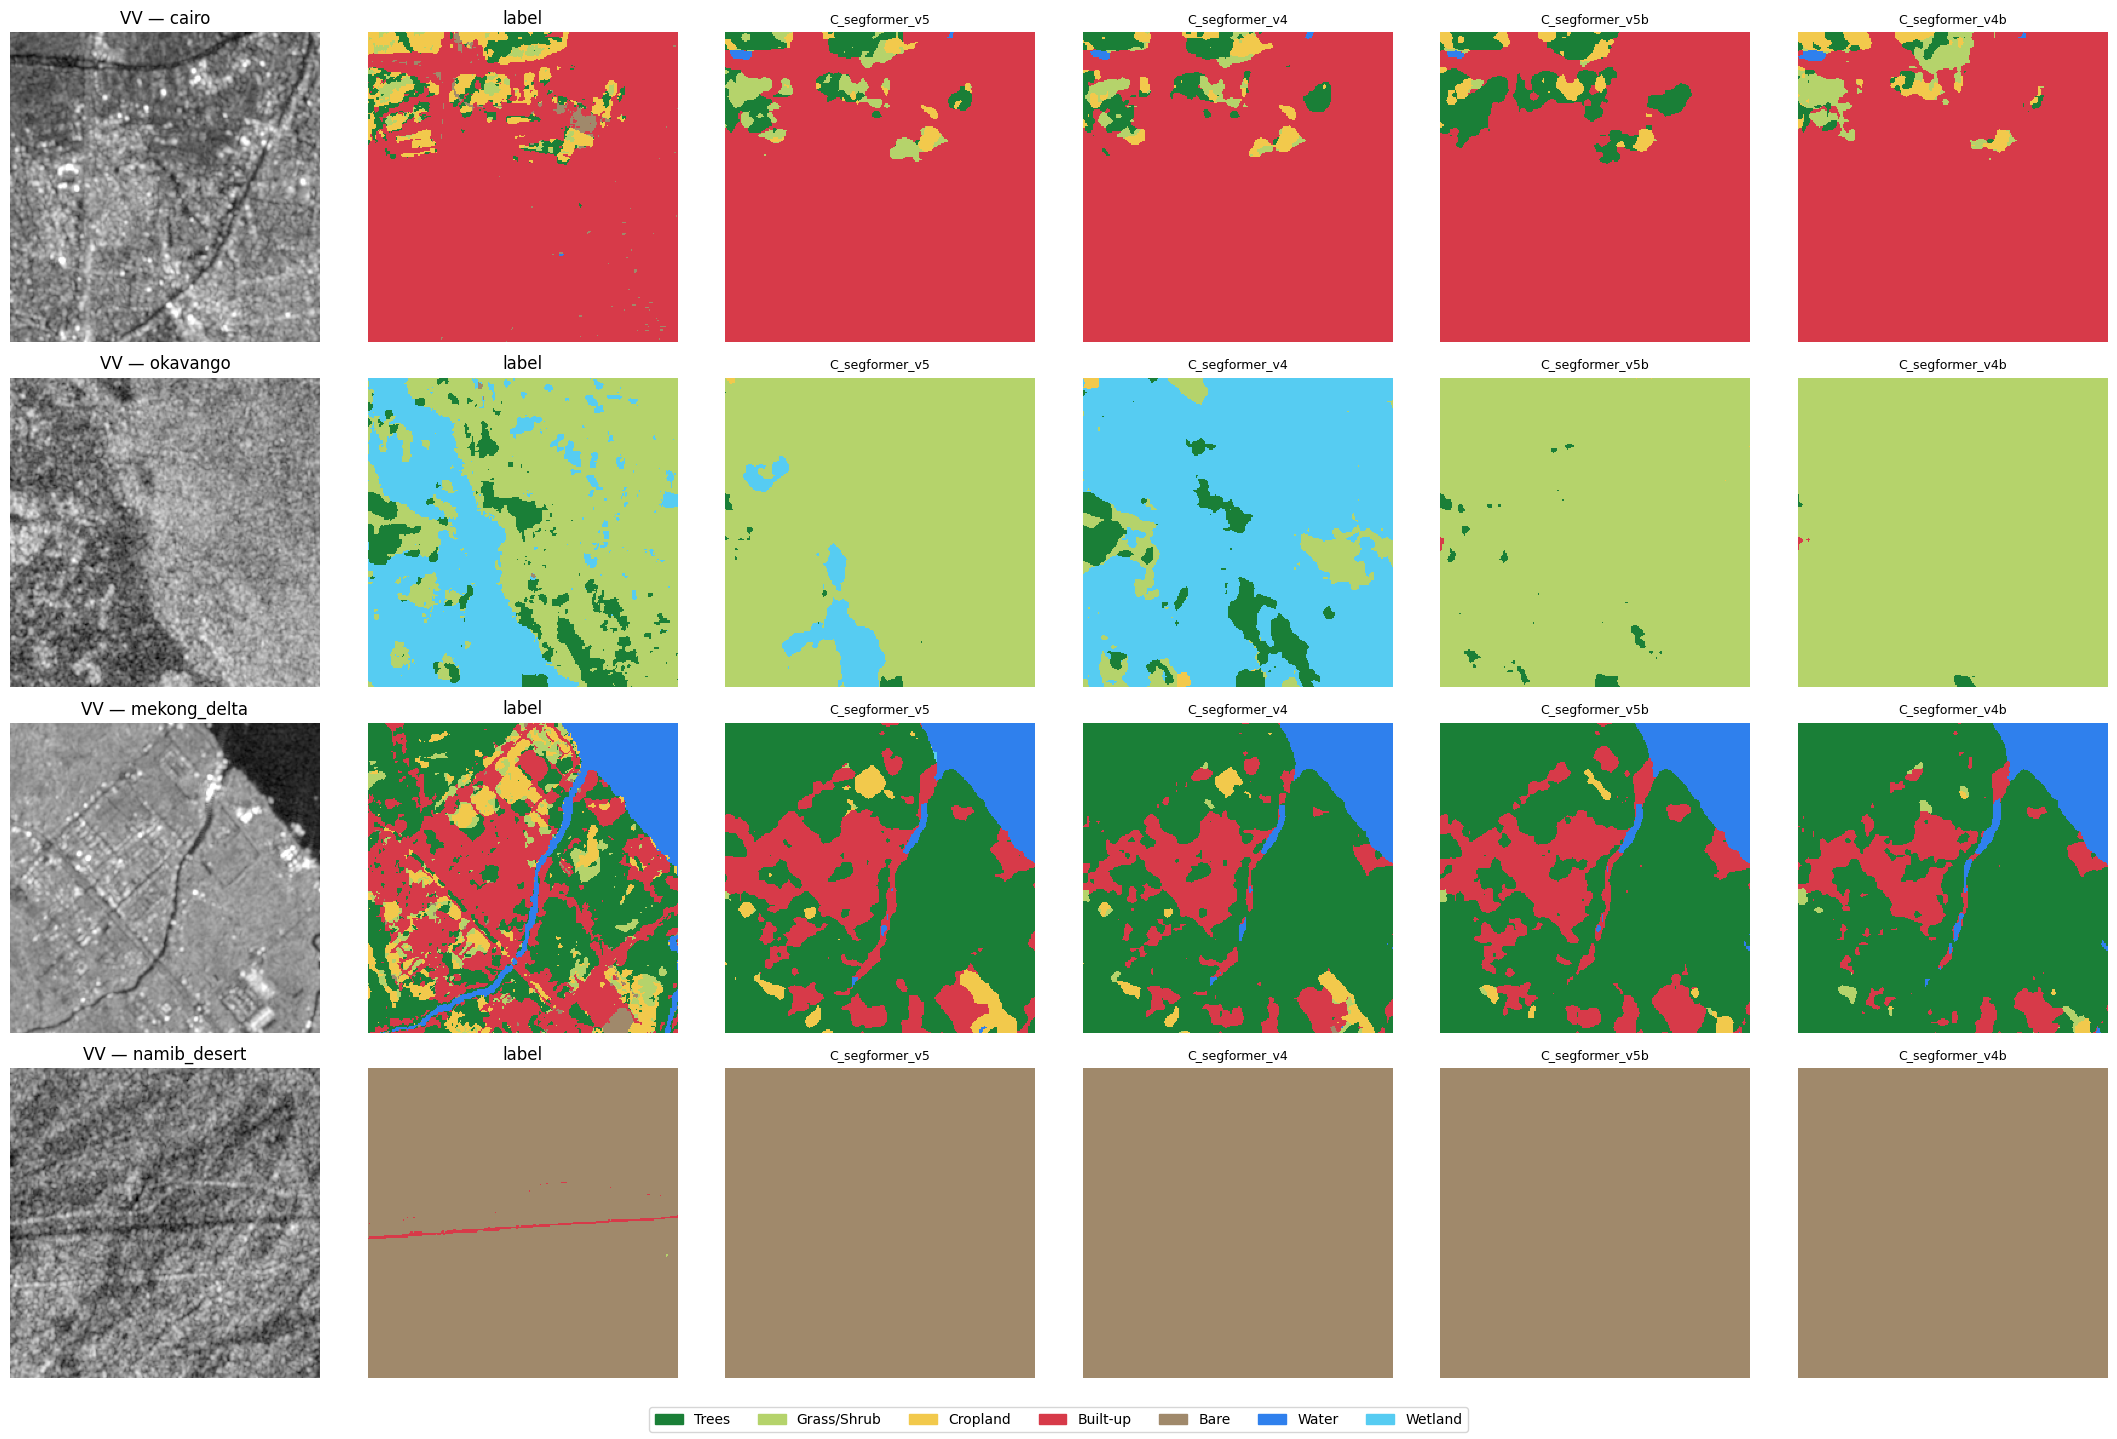

In [9]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
top = list(summary.index[:4])
models = {}
for n in top:
    m = tl.build_model(tl.arch_of(R[n]["cfg"]), None, tl.in_channels_of(R[n]["cfg"])).to(DEV)
    m.load_state_dict(torch.load(Path("runs") / n / "best.pth", map_location=DEV)); m.eval(); models[n] = m

picks = [k for k in range(len(test_ds)) if test_month[k] == 6]                       # July
picks = [picks[i] for i in np.linspace(0, len(picks) - 1, 4).astype(int)]
fig, ax = plt.subplots(len(picks), 2 + len(models), figsize=(3.6 * (2 + len(models)), 3.6 * len(picks)), squeeze=False)
for r, k in enumerate(picks):
    test_ds.configure(*norm_for(R[top[0]]["cfg"]))
    x, y = test_ds[k]; x = x[:3]
    ax[r, 0].imshow(x[0], cmap="gray"); ax[r, 0].set_title(f"VV — {test_region[k]}")
    ax[r, 1].imshow(np.ma.masked_equal(y.numpy(), IGNORE), cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest"); ax[r, 1].set_title("label")
    for c, (n, m) in enumerate(models.items()):
        with torch.no_grad():
            test_ds.configure(*norm_for(R[n]["cfg"])); inp, _ = test_ds[k]
            p = m(inp[None].to(DEV)).argmax(1)[0].cpu().numpy()
        ax[r, 2 + c].imshow(p, cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest"); ax[r, 2 + c].set_title(n, fontsize=9)
    for a in ax[r]: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=NC)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(OUT / "comparison_test_examples.png", dpi=110); plt.show()

## 7. What to write down
* Best run by **validation mIoU** → its **test** OA, mIoU, per-class IoU and F1.
* Effect of each change: v1 → v2 (longer + Lovász), SegFormer v2 → v3 (regularisation), **v2/v3 → v4 (year channels) → v4b (3-month window) → v5/v5b (more training regions)**.
* Which classes improved or got worse, generalisation per region, seasonal spread.
* Cost: parameters and training minutes.